Saving FFNN_Dataset.csv to FFNN_Dataset.csv
   Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6 Category
0   2.312741   2.292335   0.461180   2.206514   2.885498   0.586203  Class_A
1   1.589578  -2.842359   1.388463   2.019691  -1.529344   2.320215  Class_B
2   1.026707  -2.630640   2.363355   1.529290  -1.353805   2.866372  Class_B
3   2.512595   2.069056   0.802047   1.093581   1.928394  -0.205125  Class_A
4  -0.391492   2.973878   2.394791  -1.026541   0.614868  -1.956291  Class_A
5   1.310366   1.115737  -1.340006  -1.515115   0.992056  -1.013889  Class_C
6   0.247158  -2.458380   1.567940   0.174484  -1.243533   2.513919  Class_B
7   1.523540   2.529582   1.887948   2.295544   0.506445  -2.129203  Class_A
8  -0.510955   2.519283   2.654201  -0.262387   0.272868  -1.667757  Class_A
9  -1.626634   1.796849  -0.274886   1.765554   2.680479   1.133330  Class_C
Shape: (360, 7)
Feature_1    float64
Feature_2    float64
Feature_3    float64
Feature_4    float64
Feature_5

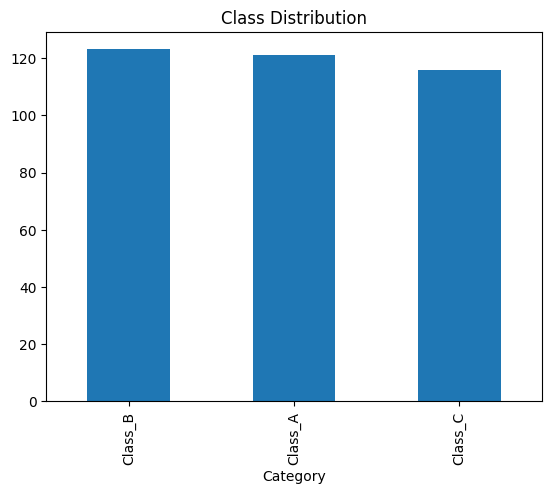

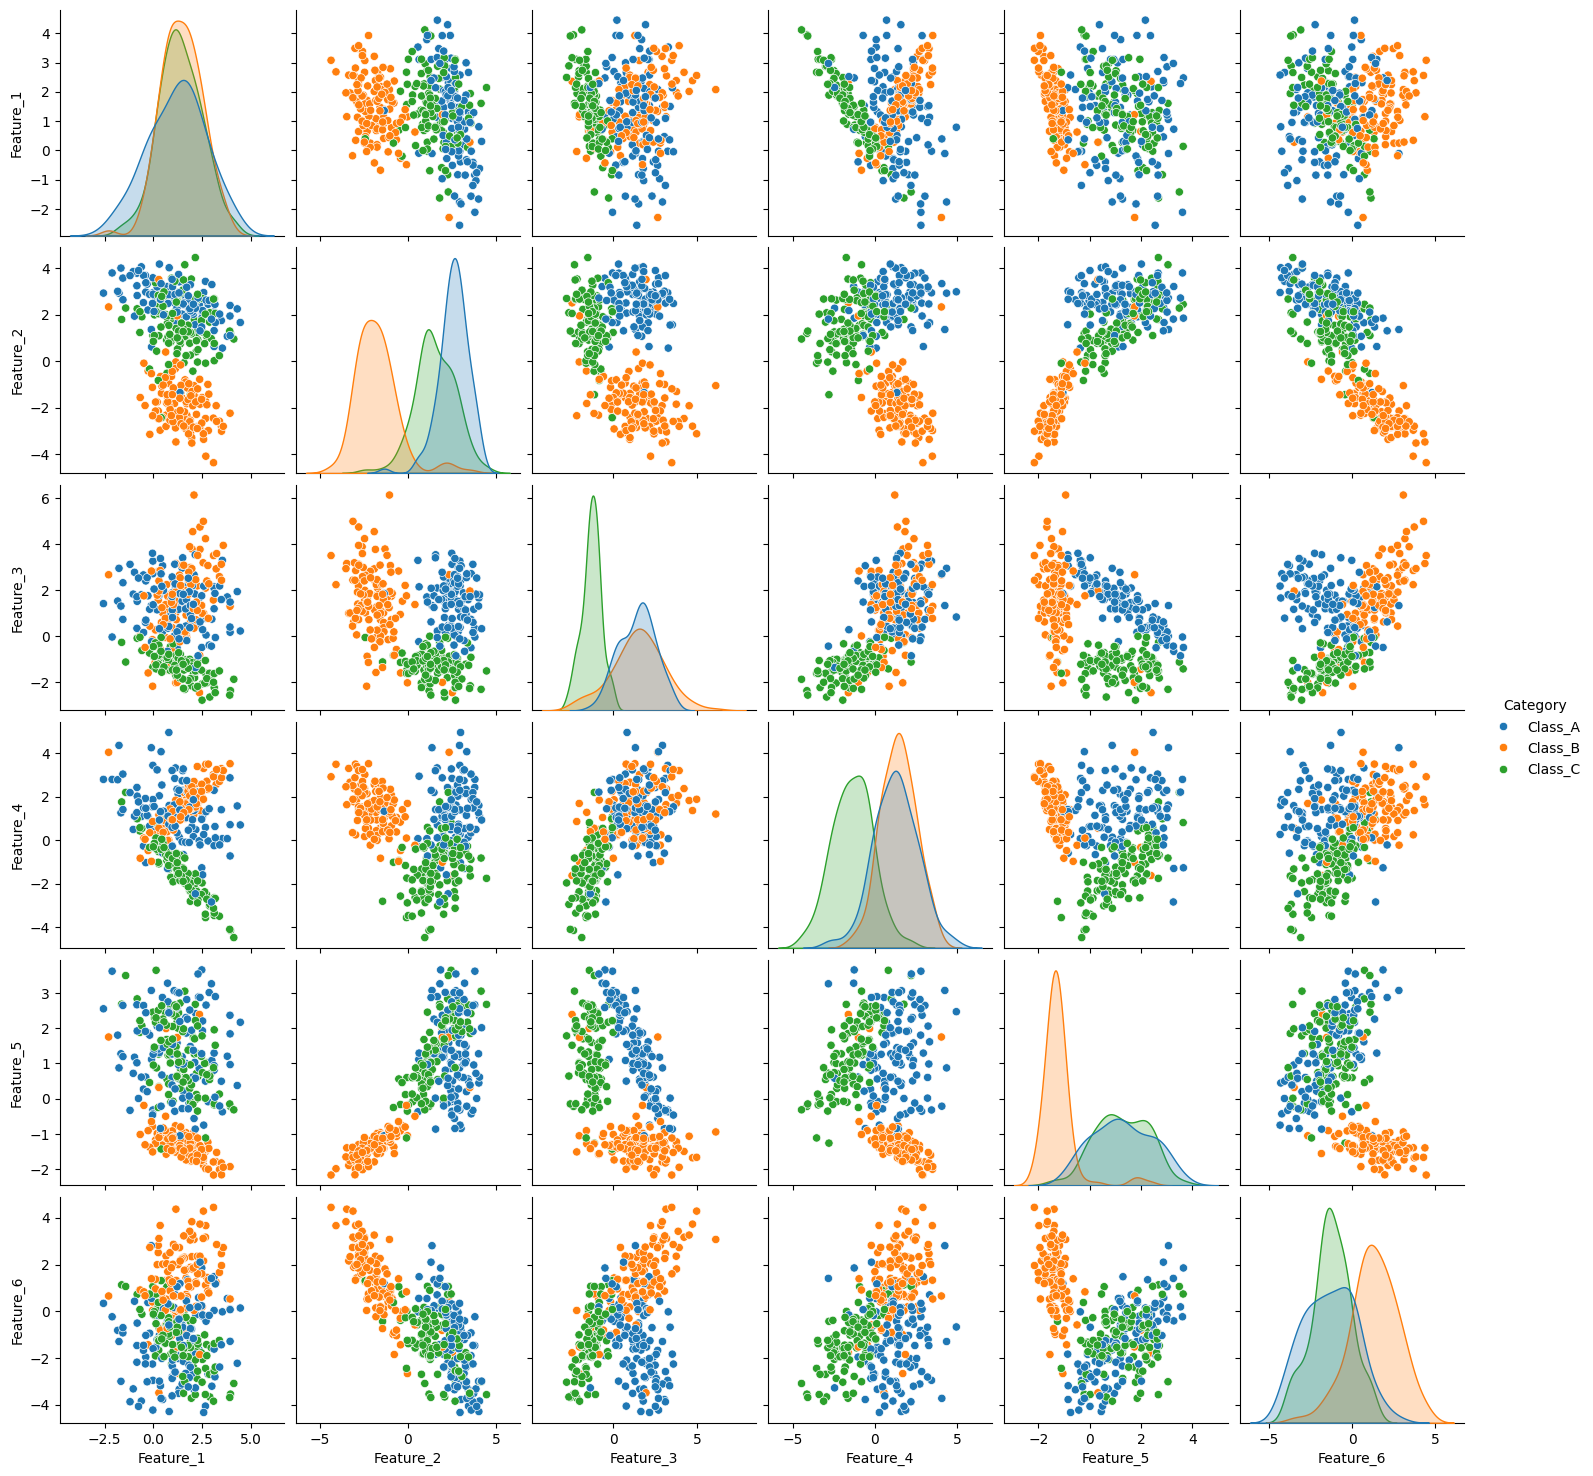

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

print(df.head(10))
print("Shape:", df.shape)
print(df.dtypes)
print(df.describe())
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

print(df['Category'].value_counts())

df['Category'].value_counts().plot(kind='bar')
plt.title("Class Distribution")
plt.show()

sns.pairplot(df, hue='Category')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

X = df.iloc[:, :6]
y = LabelEncoder().fit_transform(df['Category'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (252, 6)
Testing data: (108, 6)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(6,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 275 (1.07 KB)

 Trainable params: 275 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.2289 - loss: 1.1297 - val_accuracy: 0.4118 - val_loss: 1.0937
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3532 - loss: 1.0731 - val_accuracy: 0.4902 - val_loss: 1.0400
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.4627 - loss: 1.0217 - val_accuracy: 0.5098 - val_loss: 0.9942
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5771 - loss: 0.9716 - val_accuracy: 0.5294 - val_loss: 0.9446
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6318 - loss: 0.9210 - val_accuracy: 0.6667 - val_loss: 0.8808
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6667 - loss: 0.8642 - val_accuracy: 0.7451 - val_loss: 0.8197
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6716 - loss: 0.8122 - val_accuracy: 0.7451 - val_loss: 0.7601
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.6667 - loss: 0.7630 - val_accuracy: 0.7647 - v

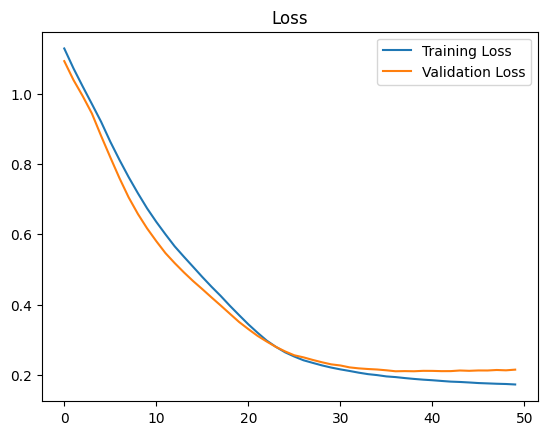

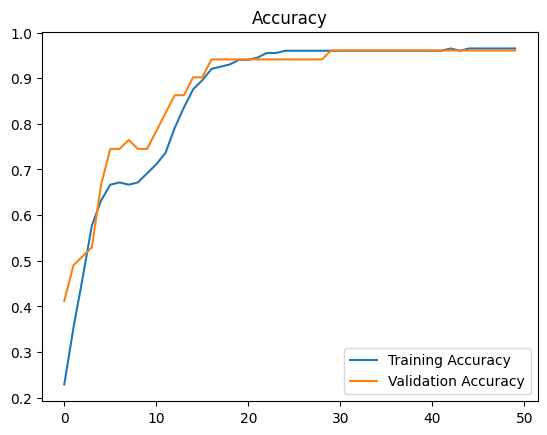

In [ ]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Loss")
plt.legend()
plt.show()

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Accuracy")
plt.legend()
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
Accuracy: 0.9722222222222222
Precision: 0.9736842105263158
Recall: 0.9729729729729729
F1-score: 0.9722168628207601
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       1.00      0.92      0.96        37
           2       0.92      1.00      0.96        35

    accuracy                           0.97       108
   macro avg       0.97      0.97      0.97       108
weighted avg       0.97      0.97      0.97       108



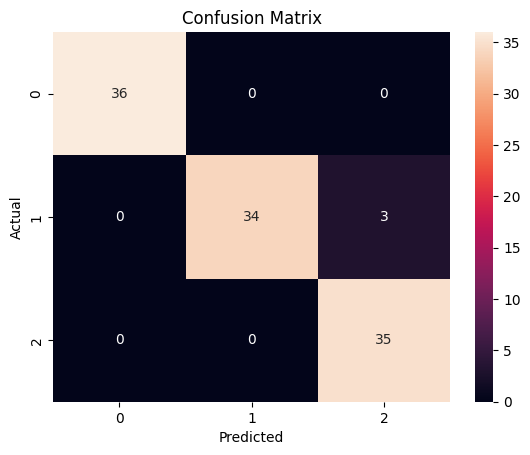

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

pred = np.argmax(model.predict(X_test), axis=1)

print("Accuracy:", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred, average='macro'))
print("Recall:", recall_score(y_test, pred, average='macro'))
print("F1-score:", f1_score(y_test, pred, average='macro'))

print(classification_report(y_test, pred))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
def build_model(two_layers):
    model = Sequential()
    model.add(Input(shape=(6,)))
    model.add(Dense(16, activation='relu'))

    if two_layers:
        model.add(Dense(8, activation='relu'))

    model.add(Dense(3, activation='softmax'))
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

results = []

for two_layers in [False, True]:
    net = build_model(two_layers)
    net.fit(X_train, y_train, epochs=50,
            batch_size=16, verbose=0)

    pred = np.argmax(net.predict(X_test, verbose=0), axis=1)
    results.append({
        'Architecture': 'Two hidden layers' if two_layers else 'One hidden layer',
        'Accuracy': accuracy_score(y_test, pred),
        'Macro F1': f1_score(y_test, pred, average='macro')
    })

print(pd.DataFrame(results))

        Architecture  Accuracy  Macro F1
0   One hidden layer  0.981481  0.981481
1  Two hidden layers  0.972222  0.972090


In [ ]:
probabilities = model.predict(X_test)

for i in range(10):
    print("Actual:", y_test[i],
          "Predicted:", pred[i],
          "Probabilities:", probabilities[i])

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
Actual: 1 Predicted: 1 Probabilities: [0.00146118 0.99622744 0.00231131]
Actual: 2 Predicted: 2 Probabilities: [0.07024009 0.04211712 0.8876428 ]
Actual: 0 Predicted: 0 Probabilities: [0.9731131  0.0223447  0.00454209]
Actual: 1 Predicted: 2 Probabilities: [0.04972056 0.21330936 0.7369701 ]
Actual: 2 Predicted: 2 Probabilities: [0.03746092 0.02531948 0.93721956]
Actual: 1 Predicted: 1 Probabilities: [6.7844545e-04 9.9817950e-01 1.1419659e-03]
Actual: 1 Predicted: 1 Probabilities: [0.03448044 0.95800424 0.00751539]
Actual: 0 Predicted: 0 Probabilities: [0.9914172  0.00668205 0.0019008 ]
Actual: 1 Predicted: 1 Probabilities: [2.1406804e-04 9.9976462e-01 2.1338736e-05]
Actual: 1 Predicted: 1 Probabilities: [4.5667496e-04 9.9937087e-01 1.7253520e-04]


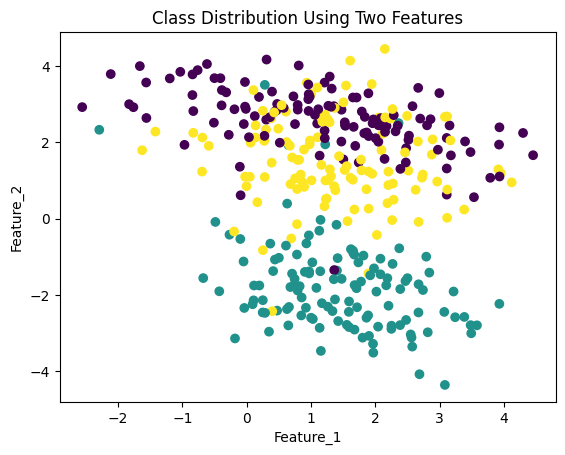

In [ ]:
plt.scatter(df['Feature_1'], df['Feature_2'],
            c=LabelEncoder().fit_transform(df['Category']))
plt.xlabel("Feature_1")
plt.ylabel("Feature_2")
plt.title("Class Distribution Using Two Features")
plt.show()

In [ ]:
print("Dataset size:", df.shape)
print("Input features:", X.shape[1])
print("Classes:", df['Category'].unique())
print("Architecture: 6 → 16 → 8 → 3")
print("Test accuracy:", accuracy_score(y_test, pred))
print("Test F1-score:", f1_score(y_test, pred, average='macro'))

Dataset size: (360, 7)
Input features: 6
Classes: ['Class_A' 'Class_B' 'Class_C']
Architecture: 6 → 16 → 8 → 3
Test accuracy: 0.9722222222222222
Test F1-score: 0.9720900236528252
